<a href="https://colab.research.google.com/github/harshinihh8164419-netizen/AIML-Colabb/blob/main/Elecbill.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1. Import libraries
!pip install -q scikit-learn tensorflow

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout

# 2. Load uploaded dataset
files_found = glob.glob(
    "/content/**/household_power_consumption.txt",
    recursive=True
)

if not files_found:
    raise FileNotFoundError("Dataset file not found in Colab!")

df = pd.read_csv(
    files_found[0], sep=";", na_values=["?"], low_memory=False
)

# 3. Preprocessing
df["Timestamp"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    dayfirst=True, errors="coerce"
)
df = df.dropna(subset=["Timestamp"])
df = df.sort_values("Timestamp").set_index("Timestamp")

features = [
    "Global_active_power", "Global_reactive_power", "Voltage",
    "Global_intensity", "Sub_metering_1",
    "Sub_metering_2", "Sub_metering_3"
]

df[features] = df[features].apply(pd.to_numeric, errors="coerce")
df[features] = df[features].interpolate(
    method="time", limit_direction="both"
).ffill().bfill()

data = df[features].iloc[:10000].copy()

# 4. Visualize consumption
data["Global_active_power"].plot(figsize=(10, 4), title="Electricity Consumption")
plt.ylabel("Power (kW)")
plt.show()

# 5. Scale data
split = int(len(data) * 0.8)

scaler_x = MinMaxScaler().fit(data[features].iloc[:split])
scaler_y = MinMaxScaler().fit(data[["Global_active_power"]].iloc[:split])

X_scaled = scaler_x.transform(data[features])
y_scaled = scaler_y.transform(data[["Global_active_power"]])

# 6. Create sequences (previous 60 minutes)
lookback = 60
X, y, indices = [], [], []

for i in range(lookback, len(data)):
    X.append(X_scaled[i-lookback:i])
    y.append(y_scaled[i, 0])
    indices.append(i)

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)
indices = np.array(indices)

train = indices < split
test = indices >= split

X_train, y_train = X[train], y[train]
X_test, y_test = X[test], y[test]

# 7. Build LSTM model
model = Sequential([
    Input(shape=(lookback, len(features))),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(optimizer="adam", loss="mse")

# 8. Train model
model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)

# 9. Predict
pred_scaled = model.predict(X_test, verbose=0)

actual = scaler_y.inverse_transform(y_test.reshape(-1, 1)).flatten()
predicted = scaler_y.inverse_transform(pred_scaled).flatten()

# 10. Calculate evaluation metrics
mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

mape = np.mean(
    np.abs(actual - predicted) / np.maximum(np.abs(actual), 1e-8)
) * 100

print("\n--- MODEL RESULTS ---")
print(f"MAE: {mae:.4f} kW")
print(f"RMSE: {rmse:.4f} kW")
print(f"MAPE: {mape:.2f}%")
print(f"Approximate Accuracy (100 - MAPE): {100 - mape:.2f}%")

# 11. Plot actual vs predicted
timestamps = data.index[indices[test]]

plt.figure(figsize=(12, 5))
plt.plot(timestamps, actual, label="Actual")
plt.plot(timestamps, predicted, label="Predicted")
plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Time")
plt.ylabel("Power (kW)")
plt.legend()
plt.grid(True)
plt.show()

# 12. Save outputs
results = pd.DataFrame({
    "Actual_kW": actual,
    "Predicted_kW": predicted
}, index=timestamps)

results.to_excel("/content/electricity_predictions.xlsx")
model.save("/content/electricity_lstm_model.keras")

print("Dataset processed, model trained, and files saved!")

In [17]:
!pip install -q scikit-learn tensorflow

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout

In [18]:
files_found = glob.glob(
    "/content/**/household_power_consumption.txt",
    recursive=True
)

if not files_found:
    raise FileNotFoundError("Dataset file not found in Colab!")

df = pd.read_csv(
    files_found[0], sep=";", na_values=["?"], low_memory=False
)

In [19]:
df["Timestamp"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    dayfirst=True, errors="coerce"
)
df = df.dropna(subset=["Timestamp"])
df = df.sort_values("Timestamp").set_index("Timestamp")

features = [
    "Global_active_power", "Global_reactive_power", "Voltage",
    "Global_intensity", "Sub_metering_1",
    "Sub_metering_2", "Sub_metering_3"
]

df[features] = df[features].apply(pd.to_numeric, errors="coerce")
df[features] = df[features].interpolate(
    method="time", limit_direction="both"
).ffill().bfill()

data = df[features].iloc[:10000].copy()


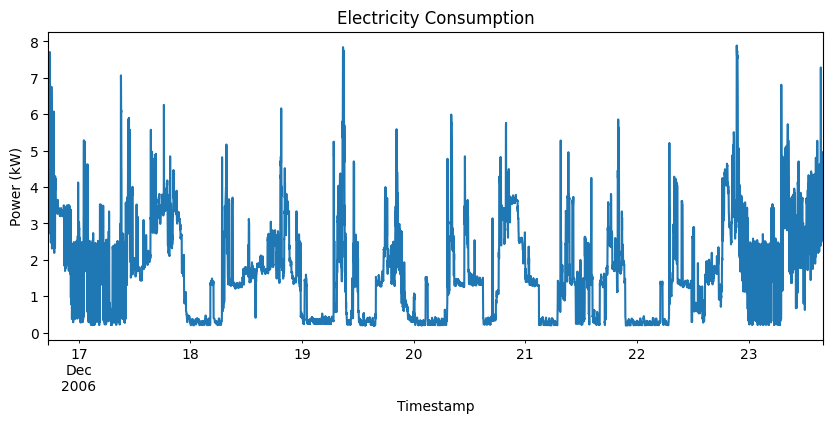

In [20]:
data["Global_active_power"].plot(figsize=(10, 4), title="Electricity Consumption")
plt.ylabel("Power (kW)")
plt.show()

In [21]:
split = int(len(data) * 0.8)

scaler_x = MinMaxScaler().fit(data[features].iloc[:split])
scaler_y = MinMaxScaler().fit(data[["Global_active_power"]].iloc[:split])

X_scaled = scaler_x.transform(data[features])
y_scaled = scaler_y.transform(data[["Global_active_power"]])


In [22]:
lookback = 60
X, y, indices = [], [], []

for i in range(lookback, len(data)):
    X.append(X_scaled[i-lookback:i])
    y.append(y_scaled[i, 0])
    indices.append(i)

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)
indices = np.array(indices)

train = indices < split
test = indices >= split

X_train, y_train = X[train], y[train]
X_test, y_test = X[test], y[test]

In [23]:
model = Sequential([
    Input(shape=(lookback, len(features))),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(optimizer="adam", loss="mse")


In [24]:
model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)

Epoch 1/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0175 - val_loss: 0.0040
Epoch 2/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0076 - val_loss: 0.0029
Epoch 3/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0056 - val_loss: 0.0022
Epoch 4/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0052 - val_loss: 0.0020
Epoch 5/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0049 - val_loss: 0.0019
Epoch 6/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0049 - val_loss: 0.0018
Epoch 7/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0047 - val_loss: 0.0017
Epoch 8/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0047 - val_loss: 0.0020
Epoch 9/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0045 - val_loss: 0.0015
Epoch 10/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0043 - val_loss: 0.0016


In [25]:
pred_scaled = model.predict(X_test, verbose=0)

actual = scaler_y.inverse_transform(y_test.reshape(-1, 1)).flatten()
predicted = scaler_y.inverse_transform(pred_scaled).flatten()

In [26]:
mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

mape = np.mean(
    np.abs(actual - predicted) / np.maximum(np.abs(actual), 1e-8)
) * 100

print("\n--- MODEL RESULTS ---")
print(f"MAE: {mae:.4f} kW")
print(f"RMSE: {rmse:.4f} kW")
print(f"MAPE: {mape:.2f}%")
print(f"Approximate Accuracy (100 - MAPE): {100 - mape:.2f}%")



--- MODEL RESULTS ---
MAE: 0.6327 kW
RMSE: 0.8305 kW
MAPE: 39.83%
Approximate Accuracy (100 - MAPE): 60.17%


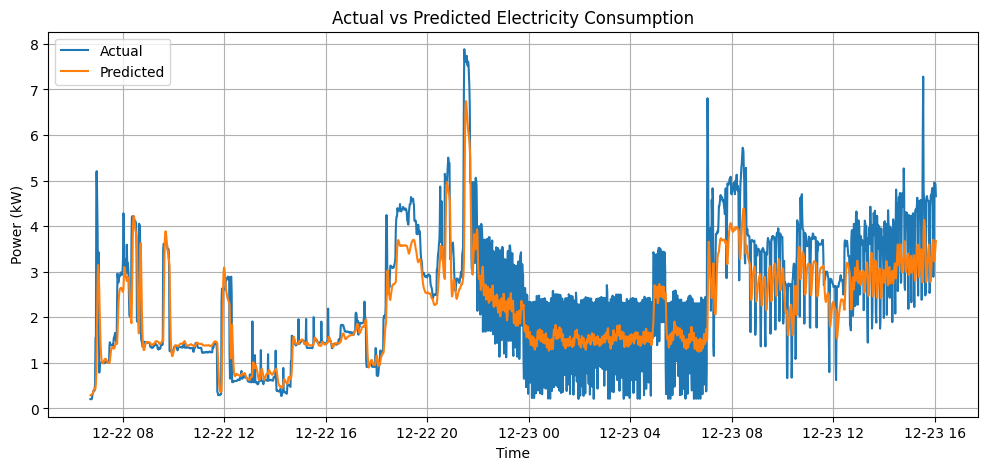

In [27]:
timestamps = data.index[indices[test]]

plt.figure(figsize=(12, 5))
plt.plot(timestamps, actual, label="Actual")
plt.plot(timestamps, predicted, label="Predicted")
plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Time")
plt.ylabel("Power (kW)")
plt.legend()
plt.grid(True)
plt.show()


In [28]:
results = pd.DataFrame({
    "Actual_kW": actual,
    "Predicted_kW": predicted
}, index=timestamps)

results.to_excel("/content/electricity_predictions.xlsx")
model.save("/content/electricity_lstm_model.keras")

print("Dataset processed, model trained, and files saved!")

Dataset processed, model trained, and files saved!
